In [1]:
!pip install scikit-learn

In [ ]:
# Support for math
import numpy as np
import math

# Plotting tools
from matplotlib import pyplot as plt
import matplotlib

import warnings
warnings.filterwarnings('ignore')

# GPy: Gaussian processes library
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF

# File tools
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd


In [ ]:
#input data:
# vol_red  = np.array([100,50,200,50,150,0,150,25,75,25,75,100])
# vol_blue = np.array([100,200,50,50,150,150,0,75,25,175,200,70])
# vol_yelo = np.array([100,50,50,200,0,150,150,200,200,100,25,130])

vol_red  = np.array( [ 82., 165., 105.,  26., 109.,  84.,  32., 214., 114., 139., 214.,15.])
vol_blue = np.array([ 39.,  76.,  78., 122., 128., 124., 153.,  37., 125., 100.,  39., 69.])
vol_yelo = np.array([177.,  57., 116., 150.,  62.,  91., 114.,  47.,  59.,  59.,  46.,214.])

In [ ]:
# Path
#df = pd.read_excel("/content/drive/MyDrive/SunLab /data/Random_Color_Incremrnt.xlsx") #12 Random colors
df = pd.read_excel("/content/drive/MyDrive/SunLab /data/02_23_Random_Color_Increment.xlsx")
df

In [ ]:
#data selection
#Example spectra
def spectra_selection(id):
  xvals = df.iloc[0, 4:]
  yvals = df.iloc[id,4:]
  return [xvals,yvals]

def interval_selection(id,min,max):
  min = np.where(df==min)[1][0]
  max = np.where(df==max)[1][0]+1

  new_x= df.iloc[0, min:max]
  new_y = df.iloc[id,min:max]
  return [new_x,new_y]


In [ ]:
#red interval area
def area_color(id,min,max):
  x,y = interval_selection(id,min,max)
  area = np.trapz(y, x)
  return area

num=len(df)-1
#For all plots
total_area = np.zeros(num)
red_area = np.zeros(num)
blue_area = np.zeros(num)
green_area = np.zeros(num)
purp_area = np.zeros(num)
low_area = np.zeros(num)
mid_area = np.zeros(num)
high_area = np.zeros(num)


#range(3,6)--> 3,4,5
for i in range(num):
  red_area[i] = area_color(i+1,496,570)
  blue_area[i] = area_color(i+1,590,620)
  green_area[i] = area_color(i+1,400,428)
  purp_area[i] = area_color(i+1,570,590)
  total_area[i] = area_color(i+1,400,700)
  low_area[i] = area_color(i+1,400,450)
  mid_area[i] = area_color(i+1,500,550)
  high_area[i] = area_color(i+1,600,650)


In [ ]:
#Sort the data
inputs = {'vol_red': vol_red, 'vol_blue': vol_blue, 'vol_yelo':vol_yelo,'area_total':sum,'red_area':low_area, 'blue_area':mid_area,'yelo_area':high_area }
input_df = pd.DataFrame(data=inputs)
input_df_red = input_df.sort_values('vol_red')
input_df_blue = input_df.sort_values('vol_blue')
input_df_yelo = input_df.sort_values('vol_yelo')

In [ ]:
#plt.plot(input_df[:,0],input_df[:,3])
plt.plot(input_df_red.loc[:, 'vol_red'],input_df_red.loc[:,'red_area'],'o')
plt.plot(input_df_blue.loc[:, 'vol_blue'],input_df_blue.loc[:,'blue_area'],'o')
plt.plot(input_df_blue.loc[:, 'vol_yelo'],input_df_blue.loc[:,'yelo_area'],'o')
#plt.plot(vol_yelo,green_area,'o')
# plt.plot(vol_red,total_area,'ro')
# plt.plot(vol_blue,total_area,'bo')
# plt.plot(vol_yelo,total_area,'yo')
# plt.plot(vol_red,sum,'ro')
# plt.plot(vol_blue,sum,'bo')
# plt.plot(vol_yelo,sum,'yo')


In [ ]:
#find line of best fit
x_sort_red = input_df_red.loc[:,'vol_red']
y_sort_red= input_df_red.loc[:,'red_area']

x_sort_blue = input_df_blue.loc[:,'vol_blue']
y_sort_blue= input_df_blue.loc[:,'blue_area']


x_sort_yelo = input_df_blue.loc[:,'vol_yelo']
y_sort_yelo= input_df_blue.loc[:,'yelo_area']

a_red, b_red = np.polyfit(x_sort_red,y_sort_red, 1)

a_blue, b_blue = np.polyfit(x_sort_blue,y_sort_blue, 1)

a_yelo, b_yelo = np.polyfit(x_sort_yelo,y_sort_yelo, 1)

#add points to plot
plt.scatter(x_sort_red,y_sort_red,color = 'r')
plt.scatter(x_sort_blue,y_sort_blue,color = 'b')
plt.scatter(x_sort_yelo,y_sort_yelo,color = 'y')


#add line of best fit to plot
plt.plot(x_sort_red, a_red*x_sort_red+b_red,color = 'r')
plt.plot(vol_blue, a_blue*vol_blue+b_blue,color = 'b')
plt.plot(vol_yelo, a_yelo*vol_yelo+b_yelo,color = 'y')

a_red, b_red


Text(0.5, 0, 'total')

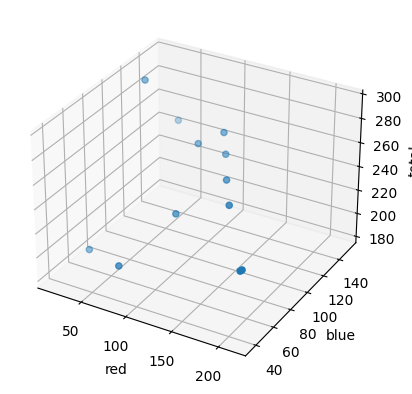

In [17]:
#Plot of LHS in 3D color coded
fig = plt.figure()
ax = fig.add_subplot(projection='3d')

ax.scatter(vol_red,vol_blue,total_area)

ax.set_xlabel('red')
ax.set_ylabel('blue')
ax.set_zlabel('total')
#ax.legend("Concentration")

#Gaussian Test


In [18]:
#Let the data set be
x = input_df[:,0].reshape(-1,1)
#x = input_df[:,0:3]
y = input_df[:,3].reshape(-1,1)

#Select random points
rng = np.random.RandomState(1)
training_indices = rng.choice(np.arange(y.size), size=12, replace=False)
X_train, Y_train = x[training_indices], y[training_indices]


# Train data set
kernel = 1 * RBF(length_scale=1.0, length_scale_bounds=(1e-2, 1e2))
gaussian_process = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=3)
gaussian_process.fit(X_train, Y_train)
gaussian_process.kernel_

# Make predictions and obtain uncertainty
y_pred, sigma = gaussian_process.predict(X_train, return_std=True)
#mean_prediction, std_prediction = gaussian_process.predict(x, return_std=True)

plt.plot(x, y,label=r"absorption",linestyle = 'dotted')

# Plot training data
plt.scatter(X_train[:, 0], Y_train, color='blue', marker='x', label='Training Data')

# Plot predicted mean
plt.plot(X_train[:, 0], y_pred, color='red',marker='x', label='Predicted Mean')

# Shade the region of uncertainty (two standard deviations)
plt.fill_between(X_train[:, 0], y_pred - 2 * sigma, y_pred + 2 * sigma, color='orange', alpha=0.2, label='Uncertainty')

plt.legend()
plt.xlabel("$color$")
plt.ylabel("absorption")
_ = plt.title("Gaussian process regression")


y_pred, sigma//1

InvalidIndexError: (slice(None, None, None), 0)